# giotto-tda – Erklärung & Beispiele

Dieses Notebook erklärt die `giotto-tda` Bibliothek mit einfachen Beispielen,
mit Fokus auf das was wir für die TDA-Pipeline brauchen:

**Ziel:** Gruppen von Kryptowährungen finden, die sich gemeinsam bewegen (*persistente Cluster*).

---

## Inhalt

1. Was ist giotto-tda?
2. Das Kernkonzept: Vietoris-Rips Filtration
3. `VietorisRipsPersistence` – der wichtigste Befehl
4. Das Diagramm-Format (`[birth, death, dim]`) – häufigster Fehler!
5. H0 Features = Cluster
6. Beispiel: 3 synthetische Cluster
7. Wie wir es für Crypto nutzen

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gtda.homology import VietorisRipsPersistence
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler

print('Imports erfolgreich')

Imports erfolgreich


---
## 1. Was ist giotto-tda?

`giotto-tda` ist eine Python-Bibliothek für **Topological Data Analysis (TDA)**.
Sie implementiert effizient die mathematischen Werkzeuge aus der Topologie für Data Science.

Was wir davon brauchen:

| Klasse | Was sie macht |
|--------|---------------|
| `VietorisRipsPersistence` | Berechnet Persistence Diagrams aus Distanzmatrizen |

Das ist der **einzige** giotto-tda Befehl den wir aktiv nutzen.
Alles andere (Cluster extrahieren, Dendrogramm, Z-Score) kommt aus `scipy` und `numpy`.

```
Distanzmatrix  →  VietorisRipsPersistence  →  Persistence Diagram  →  Cluster
   (n × n)           (gtda)                    [birth, death, dim]     (scipy)
```

---
## 2. Kernkonzept: Vietoris-Rips Filtration

**Idee:** Jeder Punkt bekommt einen wachsenden Kreis mit Radius `ε`.
Wenn sich zwei Kreise berühren, werden die Punkte verbunden.

```
ε = 0.0     ε = 0.5        ε = 1.0         ε = 1.5
A  B  C     A—B   C        A—B—C           A—B—C
D  E  F      D—E—F          D—E—F           D—E—F
             ↑              ↑                ↑
          6 Cluster      2 Cluster        1 Cluster
```

**Was wird verfolgt?**
- **Birth**: bei welchem `ε` entsteht ein Cluster?
- **Death**: bei welchem `ε` verschmilzt er mit einem grösseren?
- **Persistence = Death - Birth**: Wie lange lebte der Cluster?

→ Lange Persistence = echter Cluster
→ Kurze Persistence = Rauschen

---
## 3. `VietorisRipsPersistence` – der wichtigste Befehl

```python
from gtda.homology import VietorisRipsPersistence

vr = VietorisRipsPersistence(
    metric              = 'precomputed',  # wir liefern eigene Distanzmatrix
    homology_dimensions = [0],            # nur H0 = Cluster (keine Loops/Voids)
    max_edge_length     = 2.0,            # max Radius (Korrelationsdistanz geht bis 2)
    n_jobs              = -1,             # alle CPU-Kerne nutzen
)

diagrams = vr.fit_transform(dist_mats)
# dist_mats: shape (n_samples, n_assets, n_assets)   ← immer 3D!
# diagrams:  shape (n_samples, n_features, 3)
#                                            └── [birth, death, dim]
```

**Wichtig:** Das Input-Array muss **3-dimensional** sein: `(n_samples, n, n)`
→ Für ein einzelnes Fenster: `dist_matrix[np.newaxis, :, :]`

---
## 4. Das Diagramm-Format `[birth, death, dim]` – häufigster Fehler!

giotto-tda gibt zurück:

```
diagrams[sample_idx]  →  shape (n_features, 3)

Spalte 0 = birth  (bei welchem ε entstand das Feature)
Spalte 1 = death  (bei welchem ε starb es)
Spalte 2 = dim    (0 = Cluster/H0,  1 = Loop/H1,  2 = Void/H2)
```

**Richtig:**
```python
dgm  = diagrams[0]
h0   = dgm[dgm[:, 2] == 0]       # Spalte 2 = dim → nur H0
pers = h0[:, 1] - h0[:, 0]       # death - birth  → immer positiv
```

**Falsch (häufiger Fehler – gibt negative Persistence):**
```python
h0   = dgm[dgm[:, 0] == 0]       # ❌  Spalte 0 ist birth, nicht dim!
pers = h0[:, 2] - h0[:, 1]       # ❌  ergibt negative Werte
```

In [3]:
# Format-Demo: 4 Punkte, 2 nahe Paare → zeigt wie das Output-Format aussieht
#
#   A─B (dist 0.2)        C─D (dist 0.3)
#   A↔C = 1.5  →  A-B und C-D verschmelzen erst bei grossem eps

dist_simple = np.array([
    [0.0, 0.2, 1.5, 1.6],
    [0.2, 0.0, 1.4, 1.5],
    [1.5, 1.4, 0.0, 0.3],
    [1.6, 1.5, 0.3, 0.0],
], dtype=float)

vr = VietorisRipsPersistence(
    metric='precomputed', homology_dimensions=[0], max_edge_length=2.0, n_jobs=-1
)
diagrams = vr.fit_transform(dist_simple[np.newaxis, :, :])

dgm = diagrams[0]
print('Rohes Diagramm – Spalten: [birth, death, dim]')
print(f'  {"birth":>8}  {"death":>8}  {"dim":>4}')
for row in dgm:
    print(f'  {row[0]:>8.3f}  {row[1]:>8.3f}  {row[2]:>4.0f}')

print()
h0   = dgm[dgm[:, 2] == 0]    # ← Spalte 2 = dim
pers = h0[:, 1] - h0[:, 0]    # ← death - birth
print('H0 Features (Cluster) korrekt extrahiert:')
for i, (feat, p) in enumerate(zip(h0, pers)):
    print(f'  Feature {i+1}: birth={feat[0]:.3f}  death={feat[1]:.3f}  persistence={p:.3f}')

Rohes Diagramm – Spalten: [birth, death, dim]
     birth     death   dim
     0.000     0.200     0
     0.000     0.300     0
     0.000     1.400     0

H0 Features (Cluster) korrekt extrahiert:
  Feature 1: birth=0.000  death=0.200  persistence=0.200
  Feature 2: birth=0.000  death=0.300  persistence=0.300
  Feature 3: birth=0.000  death=1.400  persistence=1.400


---
## 5. H0 Features = Cluster

Wir interessieren uns **nur** für H0 (Dimension 0) = verbundene Komponenten = Cluster.

| Feature | Bedeutung |
|---------|----------|
| `birth = 0.0` | Jeder Punkt startet als eigener Cluster bei ε=0 |
| `death = 0.2` | Cluster stirbt (verschmilzt) bei ε=0.2 → `persistence = 0.2` |
| `death = 1.5` | Cluster bleibt lange getrennt → `persistence = 1.5` = echter Cluster |
| `death = 2.0` | Letzter Cluster (wird auf `max_edge_length` gesetzt) |

**In H0 gilt immer: birth = 0** → persistence = death.

Grosse `death`-Werte = Cluster die sehr lange getrennt blieben = echte Struktur.

---
## 6. Beispiel: 3 synthetische Cluster

Wir erstellen 3 Gruppen von Assets:
- **Gruppe A**: BTC, ETH, SOL (stark korreliert, rho ≈ 0.9)
- **Gruppe B**: LINK, UNI (mittlere Korrelation, rho ≈ 0.7)
- **Gruppe C**: USDT, USDC (Stablecoins, fast identisch – aber unabhängig von A und B)

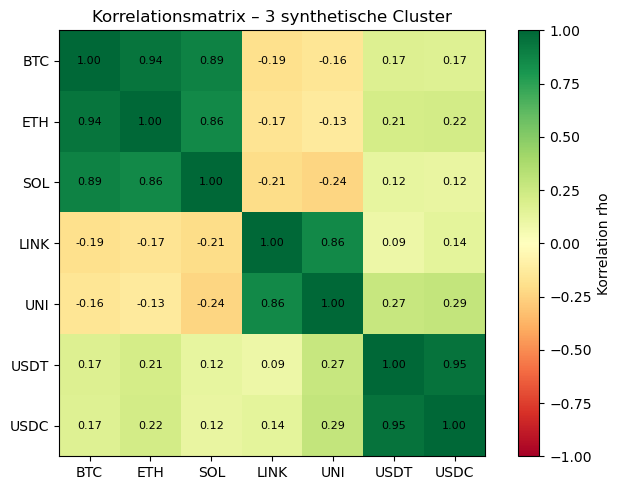

In [4]:
np.random.seed(42)
n_days = 60

market  = np.random.randn(n_days) * 0.02

# Gruppe A: folgen dem Markt stark
btc = market * 1.0  + np.random.randn(n_days) * 0.005
eth = market * 0.95 + np.random.randn(n_days) * 0.006
sol = market * 0.90 + np.random.randn(n_days) * 0.008

# Gruppe B: eigene gemeinsame Bewegung
alt  = np.random.randn(n_days) * 0.015
link = alt + np.random.randn(n_days) * 0.008
uni  = alt + np.random.randn(n_days) * 0.009

# Gruppe C: Stablecoins
usdt = np.random.randn(n_days) * 0.0005
usdc = usdt * 0.98 + np.random.randn(n_days) * 0.0002

returns = np.column_stack([btc, eth, sol, link, uni, usdt, usdc])
symbols = ['BTC', 'ETH', 'SOL', 'LINK', 'UNI', 'USDT', 'USDC']

# Korrelationsmatrix anzeigen
corr = np.corrcoef(returns.T)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(len(symbols))); ax.set_xticklabels(symbols)
ax.set_yticks(range(len(symbols))); ax.set_yticklabels(symbols)
for i in range(len(symbols)):
    for j in range(len(symbols)):
        ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, label='Korrelation rho')
ax.set_title('Korrelationsmatrix – 3 synthetische Cluster')
fig.tight_layout(); plt.show()

In [5]:
# Distanzmatrix: d = sqrt(2*(1-rho))
dist_matrix = np.sqrt(2 * (1 - np.clip(corr, -1.0, 1.0)))

# VietorisRips laufen lassen
vr = VietorisRipsPersistence(
    metric='precomputed', homology_dimensions=[0], max_edge_length=2.0, n_jobs=-1
)
diagrams = vr.fit_transform(dist_matrix[np.newaxis, :, :])

dgm  = diagrams[0]
h0   = dgm[dgm[:, 2] == 0]         # Spalte 2 = dim
pers = h0[:, 1] - h0[:, 0]         # death - birth

MIN_PERSISTENCE = 0.3

print(f'H0 Features: {len(h0)}  |  Persistent (>{MIN_PERSISTENCE}): {(pers > MIN_PERSISTENCE).sum()}')
print()
for i, j in enumerate(np.argsort(pers)[::-1]):
    label = 'PERSISTENT ✓' if pers[j] > MIN_PERSISTENCE else 'Rauschen'
    print(f'  #{i+1}: birth={h0[j,0]:.3f}  death={h0[j,1]:.3f}  persistence={pers[j]:.3f}  → {label}')

H0 Features: 6  |  Persistent (>0.3): 6

  #1: birth=0.000  death=1.248  persistence=1.248  → PERSISTENT ✓
  #2: birth=0.000  death=1.194  persistence=1.194  → PERSISTENT ✓
  #3: birth=0.000  death=0.537  persistence=0.537  → PERSISTENT ✓
  #4: birth=0.000  death=0.479  persistence=0.479  → PERSISTENT ✓
  #5: birth=0.000  death=0.350  persistence=0.350  → PERSISTENT ✓
  #6: birth=0.000  death=0.311  persistence=0.311  → PERSISTENT ✓


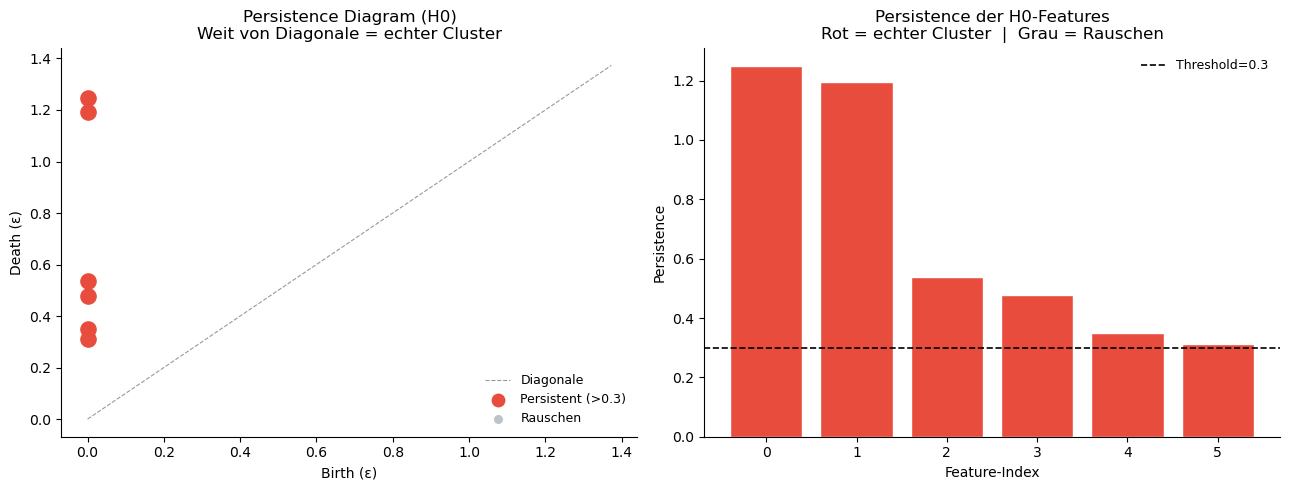

→ 6 persistente Cluster (erwartet: 3)


In [6]:
# Persistence Diagram + Barplot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax    = axes[0]
max_d = h0[:, 1].max() * 1.1
ax.plot([0, max_d], [0, max_d], 'k--', lw=0.8, alpha=0.4, label='Diagonale')
for feat, p in zip(h0, pers):
    c = '#e74c3c' if p > MIN_PERSISTENCE else '#bdc3c7'
    s = 120       if p > MIN_PERSISTENCE else 30
    ax.scatter(feat[0], feat[1], c=c, s=s, zorder=3)
ax.scatter([], [], c='#e74c3c', s=80, label=f'Persistent (>{MIN_PERSISTENCE})')
ax.scatter([], [], c='#bdc3c7', s=30, label='Rauschen')
ax.set_xlabel('Birth (ε)'); ax.set_ylabel('Death (ε)')
ax.set_title('Persistence Diagram (H0)\nWeit von Diagonale = echter Cluster')
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)

ax2    = axes[1]
idx_s  = np.argsort(pers)[::-1]
colors = ['#e74c3c' if p > MIN_PERSISTENCE else '#bdc3c7' for p in pers[idx_s]]
ax2.bar(range(len(pers)), pers[idx_s], color=colors, edgecolor='white')
ax2.axhline(MIN_PERSISTENCE, color='black', ls='--', lw=1.2, label=f'Threshold={MIN_PERSISTENCE}')
ax2.set_xlabel('Feature-Index'); ax2.set_ylabel('Persistence')
ax2.set_title('Persistence der H0-Features\nRot = echter Cluster  |  Grau = Rauschen')
ax2.legend(frameon=False, fontsize=9)
ax2.spines[['top', 'right']].set_visible(False)

fig.tight_layout(); plt.show()
print(f'→ {(pers > MIN_PERSISTENCE).sum()} persistente Cluster (erwartet: 3)')

Cluster-Mitglieder (Birth-Scale Schnitt):

  ['BTC']  (birth=0.000, persistence=1.248)
  ['BTC']  (birth=0.000, persistence=1.194)
  ['BTC']  (birth=0.000, persistence=0.537)
  ['BTC']  (birth=0.000, persistence=0.479)
  ['BTC']  (birth=0.000, persistence=0.350)
  ['BTC']  (birth=0.000, persistence=0.311)


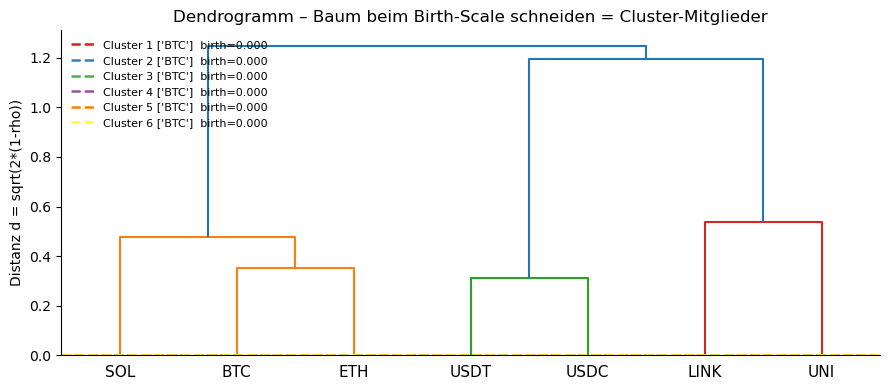

In [7]:
# Cluster-Mitglieder via Birth-Scale + Dendrogramm
Z = linkage(squareform(dist_matrix, checks=False), method='single')

print('Cluster-Mitglieder (Birth-Scale Schnitt):\n')
found = []
for j in np.argsort(pers)[::-1]:
    if pers[j] <= MIN_PERSISTENCE:
        continue
    birth  = float(h0[j, 0])
    labels = fcluster(Z, t=birth, criterion='distance')
    groups = {}
    for idx, lbl in enumerate(labels):
        groups.setdefault(lbl, []).append(symbols[idx])
    members = max(groups.values(), key=len)
    found.append((birth, pers[j], members))
    print(f'  {members}  (birth={birth:.3f}, persistence={pers[j]:.3f})')

fig, ax = plt.subplots(figsize=(9, 4))
dendrogram(Z, labels=symbols, ax=ax, leaf_rotation=0, leaf_font_size=11)
cmap = plt.cm.Set1
for i, (birth, p, members) in enumerate(found):
    ax.axhline(birth, color=cmap(i), ls='--', lw=1.8,
               label=f'Cluster {i+1} {members}  birth={birth:.3f}')
ax.set_title('Dendrogramm – Baum beim Birth-Scale schneiden = Cluster-Mitglieder')
ax.set_ylabel('Distanz d = sqrt(2*(1-rho))')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); plt.show()

---
## 7. Wie wir es für Crypto nutzen

In `02_TDA.ipynb` läuft exakt dieselbe Pipeline – nur mit echten Parquet-Daten:

```
asset_daily.parquet
    │
    ▼
log-Returns  →  Sliding Windows (30 Tage)  →  StandardScaler
    │  shape: (n_windows, 30, n_assets)
    ▼
Distanzmatrizen   d = sqrt(2*(1-rho))   für jedes Fenster
    │  shape: (n_windows, n_assets, n_assets)
    ▼
VietorisRipsPersistence.fit_transform(dist_mats)
    │  shape: (n_windows, n_features, 3)  ← [birth, death, dim]
    ▼
h0 = dgm[dgm[:, 2] == 0]   |   pers = h0[:,1] - h0[:,0]  > 0.1
    ▼
fcluster(Z, t=birth)  →  Cluster-Mitglieder
    ▼
Z-Score Spread  →  LONG Underperformer / SHORT Outperformer (wenn Spread > 2.5)
```

In [8]:
# Vollständige Pipeline in ~25 Zeilen (mit synthetischen Daten)

# 1. Sliding Windows
WINDOW   = 30
windows  = []
for i in range(len(returns) - WINDOW + 1):
    win = returns[i : i + WINDOW]
    windows.append(StandardScaler().fit_transform(win))
point_clouds = np.array(windows)                          # (n_windows, 30, 7)

# 2. Distanzmatrizen für alle Fenster
def corr_dist(win):
    return np.sqrt(2 * (1 - np.clip(np.corrcoef(win.T), -1, 1)))

dist_mats = np.array([corr_dist(w) for w in point_clouds])   # (n_windows, 7, 7)

# 3. VietorisRips auf ALLEN Fenstern
vr       = VietorisRipsPersistence(metric='precomputed', homology_dimensions=[0],
                                    max_edge_length=2.0, n_jobs=-1)
diagrams = vr.fit_transform(dist_mats)

# 4. Letztes Fenster analysieren
dgm  = diagrams[-1]
h0   = dgm[dgm[:, 2] == 0]
pers = h0[:, 1] - h0[:, 0]

print(f'Fenster: {len(diagrams)}  |  H0 Features: {len(h0)}  |  Persistent (>0.3): {(pers > 0.3).sum()}')

# 5. Cluster extrahieren
last_dist = dist_mats[-1]
Z         = linkage(squareform(last_dist, checks=False), method='single')
for j in np.argsort(pers)[::-1]:
    if pers[j] <= 0.3: continue
    labels  = fcluster(Z, t=float(h0[j, 0]), criterion='distance')
    groups  = {}
    for idx, lbl in enumerate(labels): groups.setdefault(lbl, []).append(symbols[idx])
    print(f'  Cluster: {max(groups.values(), key=len)}  (p={pers[j]:.3f})')

# 6. Z-Score Signal für letzten Tag
latest   = returns[-1]
z        = (latest - latest.mean()) / latest.std()
spread   = z.max() - z.min()
print(f'\nZ-Score Spread: {spread:.2f}')
if spread > 2.5:
    print(f'  LONG  {symbols[np.argmin(z)]:5s}  z={z.min():+.2f}')
    print(f'  SHORT {symbols[np.argmax(z)]:5s}  z={z.max():+.2f}')
else:
    print('  Kein Trade (Spread zu klein)')

Fenster: 31  |  H0 Features: 6  |  Persistent (>0.3): 4
  Cluster: ['BTC']  (p=1.155)
  Cluster: ['BTC']  (p=1.002)
  Cluster: ['BTC']  (p=0.689)
  Cluster: ['BTC']  (p=0.501)

Z-Score Spread: 2.71
  LONG  USDC   z=-1.05
  SHORT ETH    z=+1.66


---
## Zusammenfassung: Was du von giotto-tda wissen musst

| Thema | Merke |
|-------|-------|
| **Input** | `dist_mats` shape `(n_samples, n, n)` – immer 3D! |
| **Output** | `diagrams` shape `(n_samples, n_features, 3)` |
| **Spalten** | `[birth, death, dim]` – Spalte 2 ist die Dimension! |
| **H0 filtern** | `dgm[dgm[:, 2] == 0]` |
| **Persistence** | `h0[:, 1] - h0[:, 0]` (death - birth, immer positiv) |
| **metric** | `'precomputed'` wenn eigene Distanzmatrix |
| **max_edge_length** | `2.0` für Korrelationsdistanz (Range 0–2) |

**giotto-tda macht NUR den TDA-Teil.**
Cluster-Extraktion, Dendrogramm, Z-Scores → das ist `scipy` + `numpy`.